平均周期为：1.2天
下一个资金流入的日期：2024-01-09 04:48:00


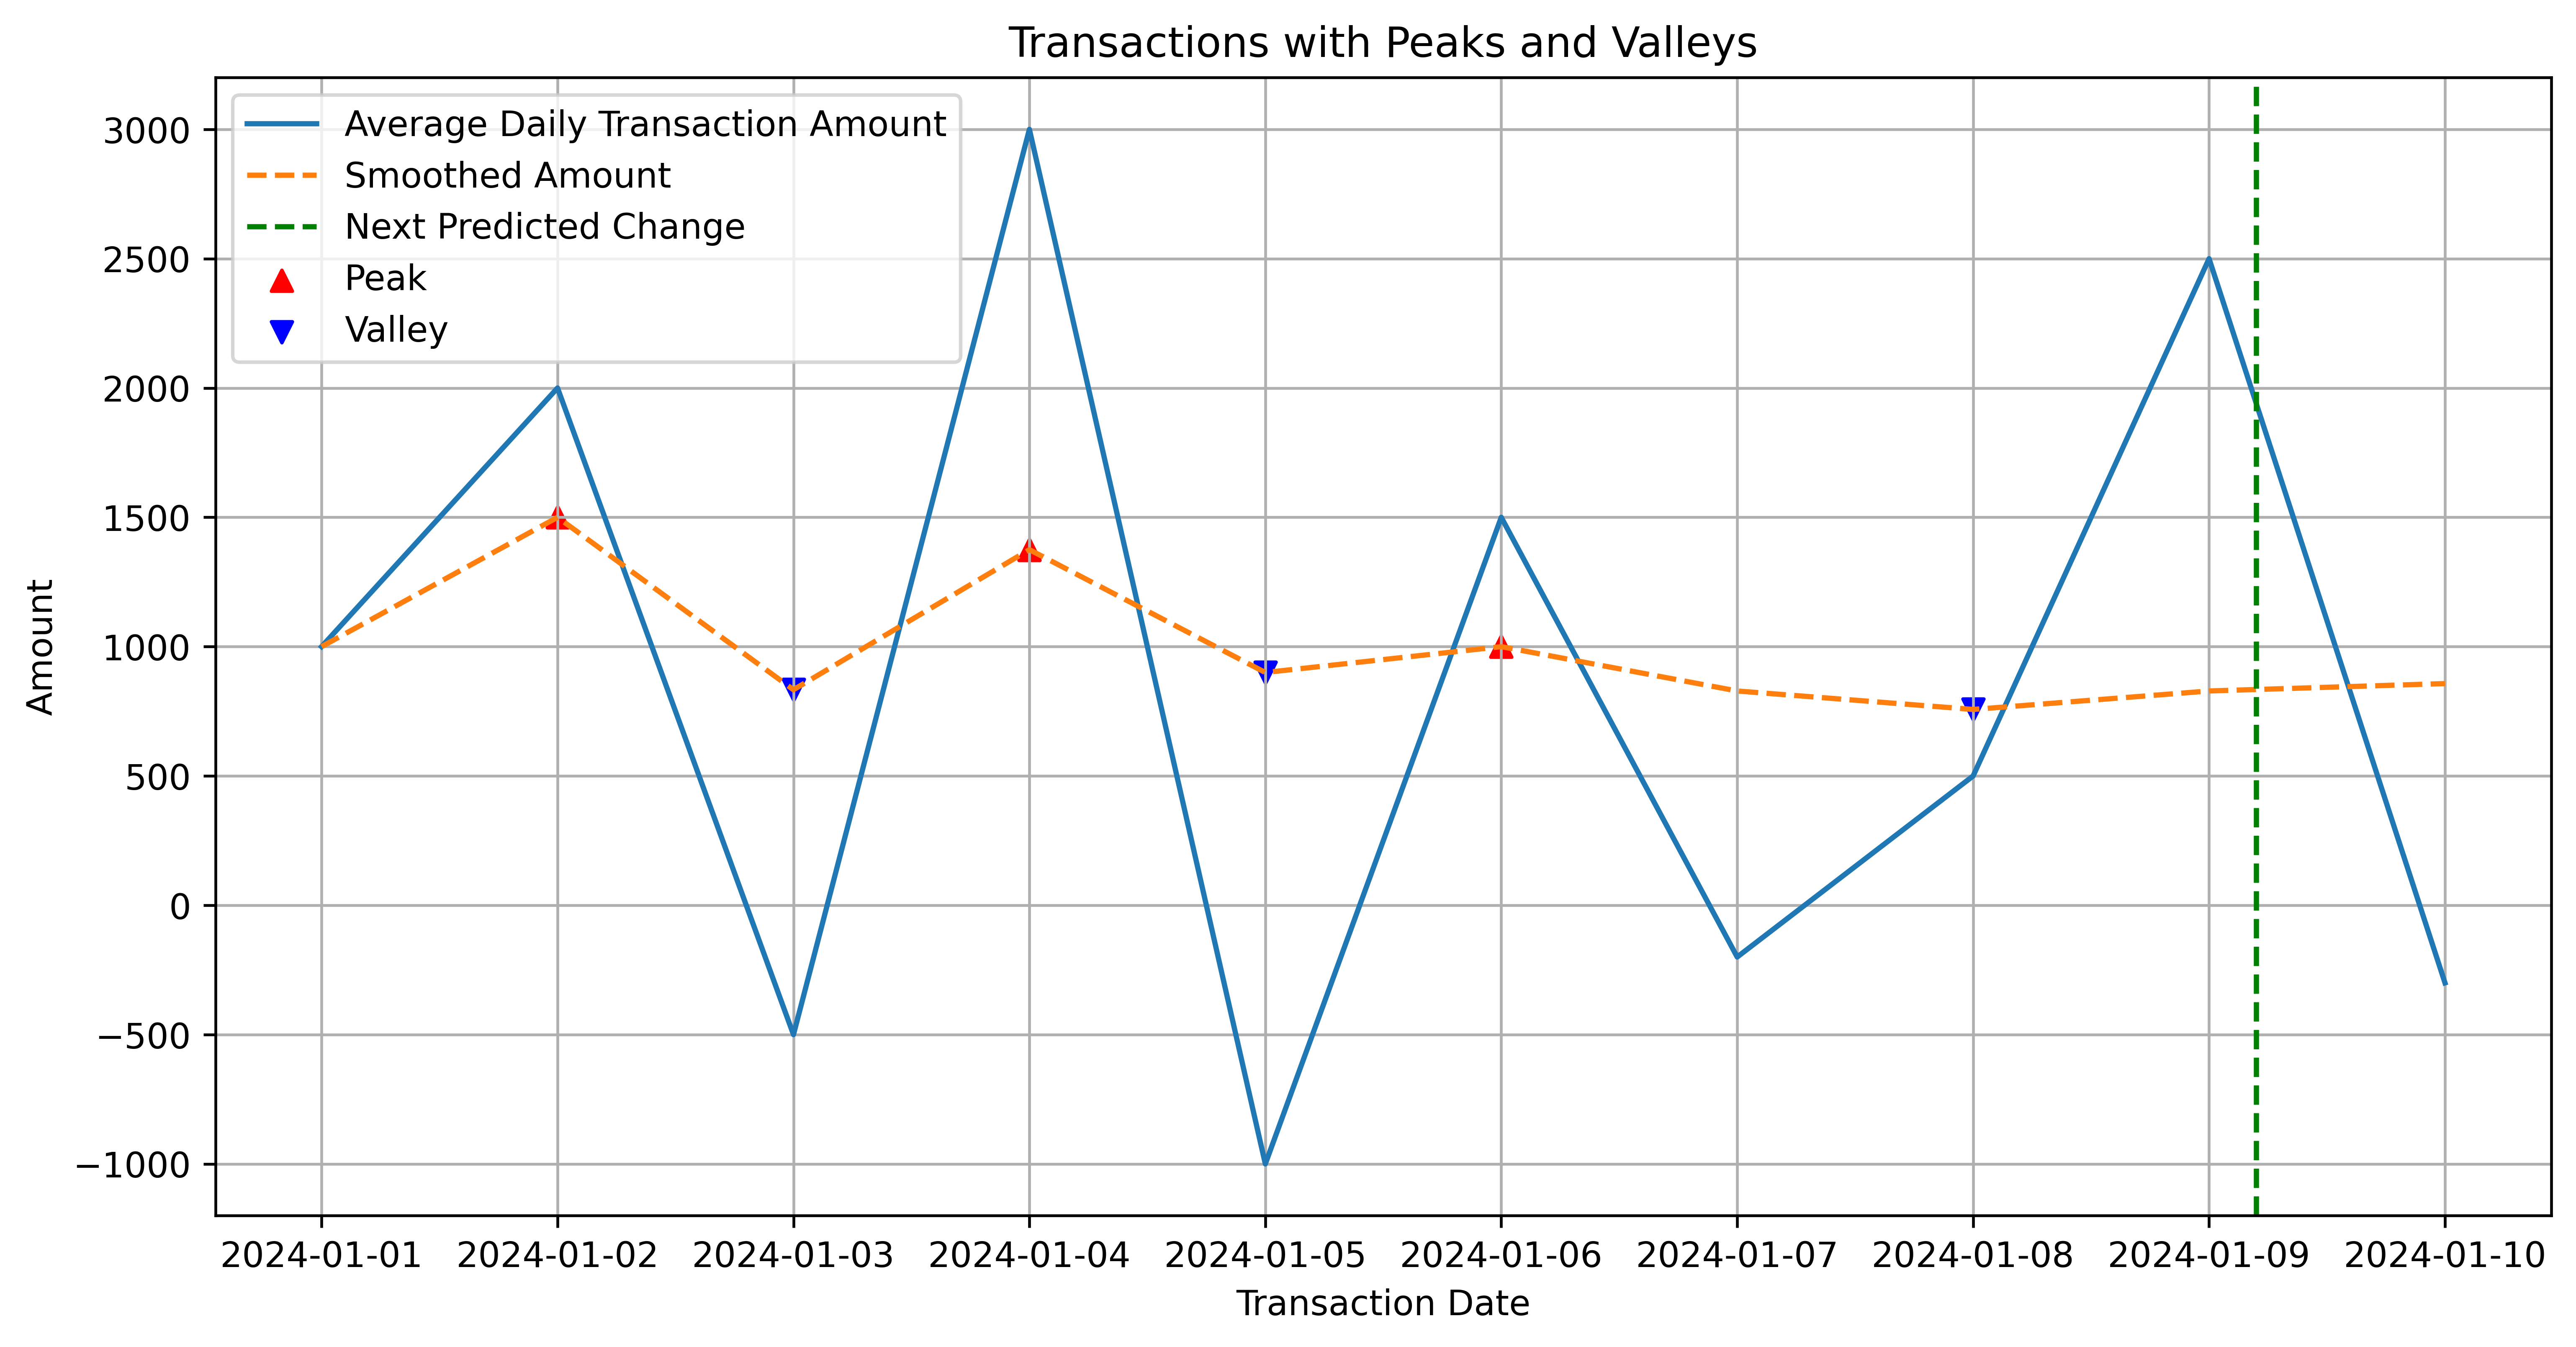

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# 模拟数据
data = {
    'customer_id': [1]*10,
    'transaction_timestamp': pd.date_range(start='2024-01-01', periods=10, freq='D'),
    'transaction_amount': [1000, 2000, -500, 3000, -1000, 1500, -200, 500, 2500, -300]
}

df = pd.DataFrame(data)

# 将时间戳汇总到按天，并计算平均值
df['transaction_date'] = df['transaction_timestamp'].dt.date
daily_avg = df.groupby('transaction_date')['transaction_amount'].mean().reset_index()
daily_avg['transaction_date'] = pd.to_datetime(daily_avg['transaction_date'])

# 计算滑动平均值
daily_avg['smoothed_amount'] = daily_avg['transaction_amount'].rolling(window=7, min_periods=1).mean()

# 计算波峰波谷
daily_avg['point_type'] = 'normal'
daily_avg.loc[(daily_avg['smoothed_amount'] > daily_avg['smoothed_amount'].shift(1)) & (daily_avg['smoothed_amount'] > daily_avg['smoothed_amount'].shift(-1)), 'point_type'] = 'peak'
daily_avg.loc[(daily_avg['smoothed_amount'] < daily_avg['smoothed_amount'].shift(1)) & (daily_avg['smoothed_amount'] < daily_avg['smoothed_amount'].shift(-1)), 'point_type'] = 'valley'

# 预测下一个波峰或波谷
last_point = daily_avg.loc[daily_avg['point_type'] != 'normal'].iloc[-1]
avg_cycle_length = (daily_avg.loc[daily_avg['point_type'] != 'normal']['transaction_date'].diff().dt.days).mean()

print('平均周期为：{}天'.format(avg_cycle_length))

next_predicted_date = last_point['transaction_date'] + pd.Timedelta(days=avg_cycle_length)
print('下一个资金流入的日期：{}'.format(next_predicted_date))
# 可视化
plt.figure(figsize=(12, 6),dpi=600)
plt.plot(daily_avg['transaction_date'], daily_avg['transaction_amount'], label='Average Daily Transaction Amount')
plt.plot(daily_avg['transaction_date'], daily_avg['smoothed_amount'], label='Smoothed Amount', linestyle='--')
plt.scatter(daily_avg.loc[daily_avg['point_type'] == 'peak', 'transaction_date'],
            daily_avg.loc[daily_avg['point_type'] == 'peak', 'smoothed_amount'],
            color='red', label='Peak', marker='^')
plt.scatter(daily_avg.loc[daily_avg['point_type'] == 'valley', 'transaction_date'],
            daily_avg.loc[daily_avg['point_type'] == 'valley', 'smoothed_amount'],
            color='blue', label='Valley', marker='v')
plt.axvline(x=next_predicted_date, color='green', linestyle='--', label='Next Predicted Change')
plt.legend()
plt.xlabel('Transaction Date')
plt.ylabel('Amount')
plt.title('Transactions with Peaks and Valleys')
plt.grid(True)
plt.savefig('./images/Transactions_Predict_window.png', dpi=600)
plt.show()


平均周期为：1.125天
下一个资金流入的日期：2024-01-11 03:00:00


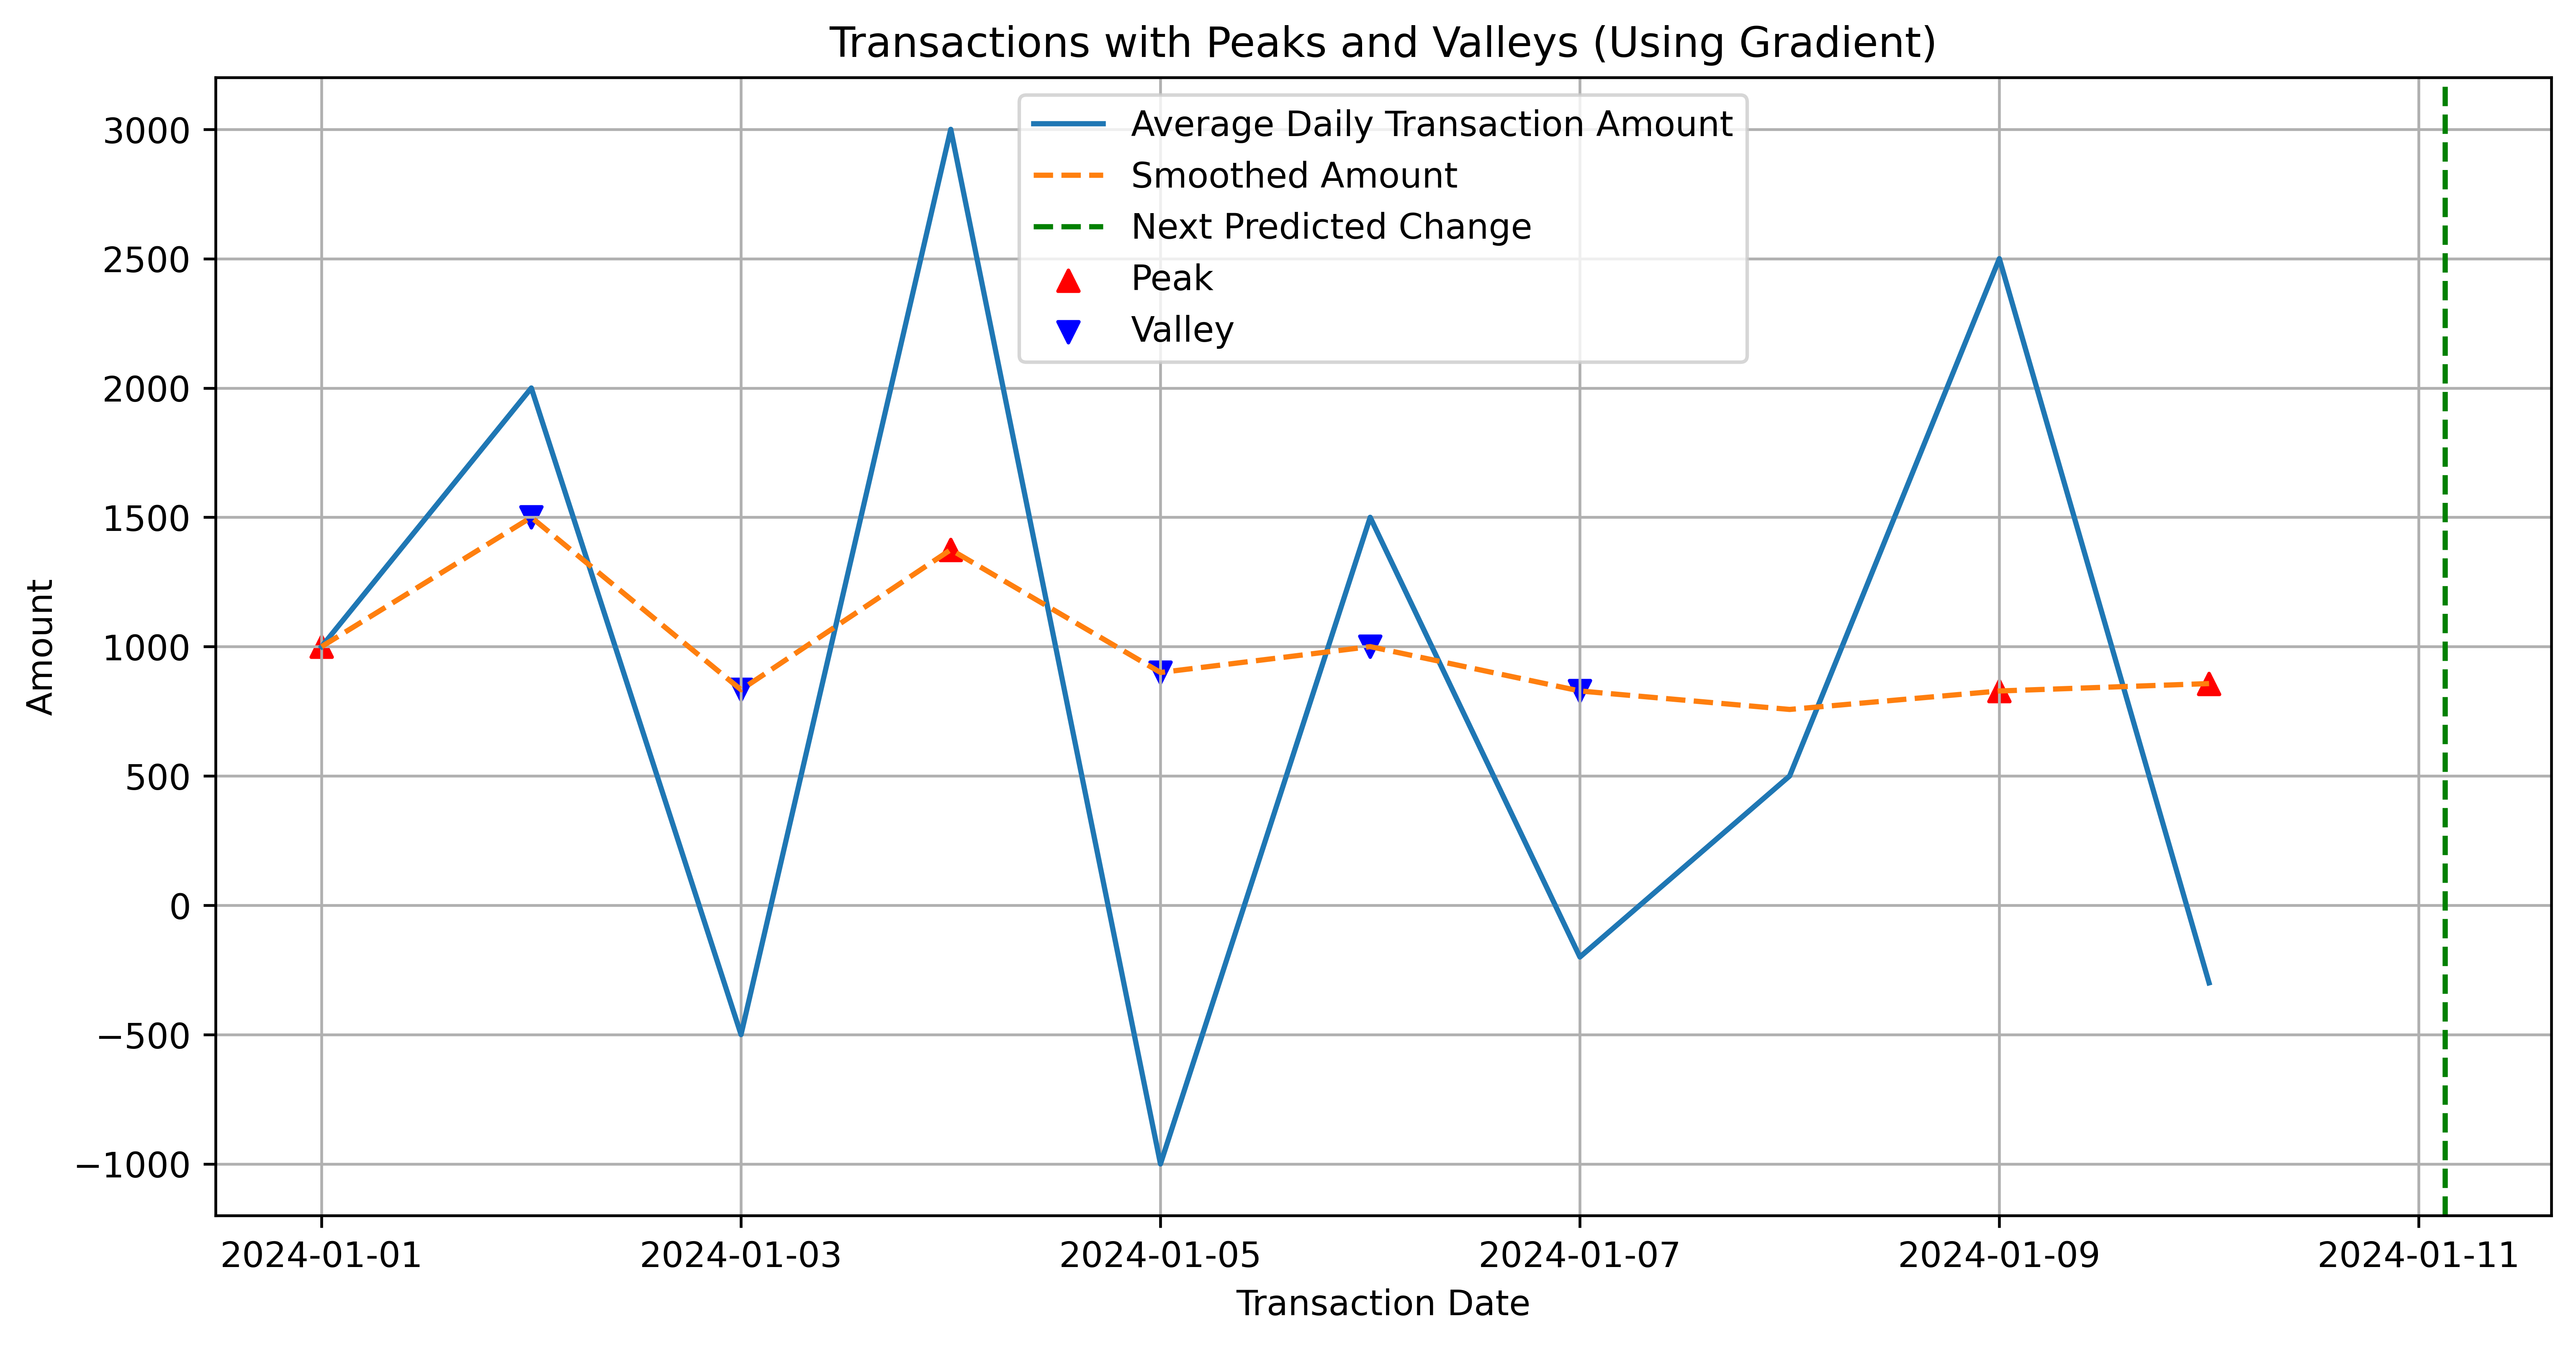

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 模拟数据
data = {
    'customer_id': [1]*10,
    'transaction_timestamp': pd.date_range(start='2024-01-01', periods=10, freq='D'),
    'transaction_amount': [1000, 2000, -500, 3000, -1000, 1500, -200, 500, 2500, -300]
}

df = pd.DataFrame(data)

# 将时间戳汇总到按天，并计算平均值
df['transaction_date'] = df['transaction_timestamp'].dt.date
daily_avg = df.groupby('transaction_date')['transaction_amount'].mean().reset_index()
daily_avg['transaction_date'] = pd.to_datetime(daily_avg['transaction_date'])

# 计算滑动平均值
daily_avg['smoothed_amount'] = daily_avg['transaction_amount'].rolling(window=7, min_periods=1).mean()

# 计算一阶导数
daily_avg['gradient'] = np.gradient(daily_avg['smoothed_amount'])

# 找到波峰和波谷
daily_avg['point_type'] = 'normal'
daily_avg.loc[daily_avg['gradient'] > 0, 'point_type'] = 'peak'
daily_avg.loc[daily_avg['gradient'] < 0, 'point_type'] = 'valley'

# 预测下一个波峰或波谷
last_point = daily_avg.loc[daily_avg['point_type'] != 'normal'].iloc[-1]
avg_cycle_length = (daily_avg.loc[daily_avg['point_type'] != 'normal']['transaction_date'].diff().dt.days).mean()
print('平均周期为：{}天'.format(avg_cycle_length))

next_predicted_date = last_point['transaction_date'] + pd.Timedelta(days=avg_cycle_length)
print('下一个资金流入的日期：{}'.format(next_predicted_date))

# 可视化
plt.figure(figsize=(12, 6), dpi=600)
plt.plot(daily_avg['transaction_date'], daily_avg['transaction_amount'], label='Average Daily Transaction Amount')
plt.plot(daily_avg['transaction_date'], daily_avg['smoothed_amount'], label='Smoothed Amount', linestyle='--')
plt.scatter(daily_avg.loc[daily_avg['point_type'] == 'peak', 'transaction_date'],
            daily_avg.loc[daily_avg['point_type'] == 'peak', 'smoothed_amount'],
            color='red', label='Peak', marker='^')
plt.scatter(daily_avg.loc[daily_avg['point_type'] == 'valley', 'transaction_date'],
            daily_avg.loc[daily_avg['point_type'] == 'valley', 'smoothed_amount'],
            color='blue', label='Valley', marker='v')
plt.axvline(x=next_predicted_date, color='green', linestyle='--', label='Next Predicted Change')
plt.legend()
plt.xlabel('Transaction Date')
plt.ylabel('Amount')
plt.title('Transactions with Peaks and Valleys (Using Gradient)')
plt.grid(True)
plt.savefig('./images/Transactions_Predict.png', dpi=600)
plt.show()
